In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
%cd /content/drive/MyDrive/빅데이터의사결정분석/Project

/content/drive/MyDrive/빅데이터의사결정분석/Project


In [5]:
!pip install -q contractions

# **라이브러리 호출**

In [41]:
import numpy as np
import pandas as pd

# 시각화 라이브러리
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import seaborn as sns

# 파일과 이미지 처리 라이브러리
from PIL import Image

# 텍스트 처리 및 자연어 처리(NLP) 라이브러리
import re
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from bs4 import BeautifulSoup
import contractions
from sklearn.feature_extraction.text import TfidfVectorizer
from collections import Counter, defaultdict
from itertools import combinations

# 네트워크 분석 라이브러리
import networkx as nx

# 진행 상태 표시 및 반복 작업 진행 표시 라이브러리
from tqdm import tqdm
tqdm.pandas()

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.inspection import permutation_importance

# **Utils**

In [42]:
def preprocess_text_lemmatized(text, normalization_dict=None):

    '''
    1. HTML 태그 제거
    2. 특정 단어 정규화 (옵션)
    3. 특수 문자 제거
    4. 모든 문자를 소문자로 변환
    5. 텍스트를 토큰화 및 불용어 제거
    6. 표제어 추출 및 원형 복원
    7. 표제어 추출 리스트를 String 형식으로 변경
    '''

  # HTML 태그 제거
    text_no_html = BeautifulSoup(text, "html.parser").get_text()

  # 특정 단어 정규화 (옵션)
    if normalization_dict:
        for old, new in normalization_dict.items():
            text_no_html = text_no_html.replace(old, new)

  # 특수 문자 제거
    text_no_specials = re.sub(r'[^a-zA-Z]', ' ', text_no_html)

  # 여러 공백을 하나로 축소 및 공백 정리
  # 띄어쓰기가 여럿 있으면, 띄어쓰기 하나로 만들어줌
    text_clean = re.sub(r'\s+', ' ', text_no_specials).strip()

  # 모든 문자를 소문자로 변환
    texts_lower = text_clean.lower()

  # 텍스트를 토큰화 및 불용어 제거
    tokens = word_tokenize(texts_lower)
    filtered_tokens = [word for word in tokens if word not in stopwords.words('english')]

  # lemmatizer Class 호출
    lemmatizer = WordNetLemmatizer()

  # 리스트 형태의 출력을 DataFrame에 저장할 수 있도록 String으로 변환해줌
    lemmatized_tokens = ' '.join([lemmatizer.lemmatize(word) for word in filtered_tokens])

    return lemmatized_tokens

In [43]:
def preprocess_text_stemmed(text, normalization_dict=None):
    '''
    1. HTML 태그 제거
    2. 특정 단어 정규화 (옵션)
    3. 특수 문자 제거
    4. 모든 문자를 소문자로 변환
    5. 텍스트를 토큰화 및 불용어 제거
    6. 어간 추출 및 원형 복원
    7. 어간 추출 리스트를 String 형식으로 변경
    '''

  # HTML 태그 제거
    text_no_html = BeautifulSoup(text, "html.parser").get_text()

  # 특정 단어 정규화
    if normalization_dict:
        for old, new in normalization_dict.items():
            text_no_html = text_no_html.replace(old, new)

  # 특수 문자 제거
    text_no_specials = re.sub(r'[^a-zA-Z]', ' ', text_no_html)

  # 여러 공백을 하나로 축소 및 공백 정리
  # 띄어쓰기가 여럿 있으면, 띄어쓰기 하나로 만들어줌
    text_clean = re.sub(r'\s+', ' ', text_no_specials).strip()

  # 모든 문자를 소문자로 변환
    texts_lower = text_clean.lower()

  # 텍스트를 토큰화 및 불용어 제거
    tokens = word_tokenize(texts_lower)
    filtered_tokens = [word for word in tokens if word not in stopwords.words('english')]

  # 어간 추출 및 원형 복원
    stemmer = PorterStemmer()

  # 리스트 형태의 출력을 DataFrame에 저장할 수 있도록 String으로 변환해줌
    stemmed_tokens = ' '.join([stemmer.stem(word) for word in filtered_tokens])

    return stemmed_tokens

In [44]:
def filter_text_by_frequency(df, column_name, min_frequency, out_column_name):

    '''
    1. 데이터프레임의 모든 텍스트를 하나의 문자열로 합치기
    2. 토큰화하여 단어의 빈도 계산하기
    3. 특정 빈도 이하의 단어 제거하기
    4. 필터링된 단어들로 새로운 텍스트 집합 생성
    5. 필터링된 텍스트를 새로운 데이터프레임 컬럼에 저장
    '''

  # 1. 데이터프레임의 모든 텍스트를 하나의 문자열로 합치기
    all_text = ' '.join(df[column_name])

  # 2. 토큰화하여 단어의 빈도 계산하기
    tokens = word_tokenize(all_text)
    word_counts = Counter(tokens)

  # 3. 특정 빈도 이하의 단어 제거하기
    filtered_words = [word for word, count in word_counts.items() if count > min_frequency]

  # 4. 필터링된 단어들로 새로운 텍스트 집합 생성
    filtered_texts = [' '.join(word for word in word_tokenize(text) if word in filtered_words) for text in df[column_name]]

  # 필터링된 텍스트를 새로운 데이터프레임 컬럼에 저장
    df[out_column_name] = filtered_texts

    return df

# **데이터 전처리**

In [45]:
import warnings
warnings.filterwarnings('ignore')

In [5]:
import nltk
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to ~/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [46]:
review = pd.read_csv('project_review_helpful.csv')

In [47]:
print(review.shape)
review.head()

(24838, 21)


In [48]:
# 진짜 리뷰만 리뷰 작성자가 명시되어 있음
review.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24838 entries, 0 to 24837
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   rating                    24838 non-null  int64  
 1   reviewer_url              12419 non-null  object 
 2   review_text               24838 non-null  object 
 3   photo                     24838 non-null  int64  
 4   location                  24838 non-null  int64  
 5   depth                     24838 non-null  int64  
 6   text_structure            24838 non-null  float64
 7   Cognition                 24838 non-null  float64
 8   Affect                    24838 non-null  float64
 9   emotion                   24838 non-null  float64
 10  Social                    24838 non-null  float64
 11  Perception                24838 non-null  float64
 12  motion                    24838 non-null  float64
 13  Psychological Distancing  24838 non-null  float64
 14  fake  

In [49]:
# 전처리 함수 적용
review['stemmed_text'] = review['review_text'].progress_apply(preprocess_text_stemmed)
review['lemmatized_text'] = review['review_text'].progress_apply(preprocess_text_lemmatized)

review.head()

100%|██████████| 24838/24838 [01:18<00:00, 317.81it/s]


In [56]:
# stemmting, lemmatize 한 단어들 중에서 5개 이하로 언급된 단어 제외
filter_text_by_frequency(review, 'stemmed_text', min_frequency=5, out_column_name='filter_stemmed_text')
filter_text_by_frequency(review, 'lemmatized_text', min_frequency=5, out_column_name='filter_lemmatized_text')

In [57]:
review

# **글자 길이의 전체분포**
- 500자 이상을 넘는 데이터는 많지 않아 보임

<Axes: >

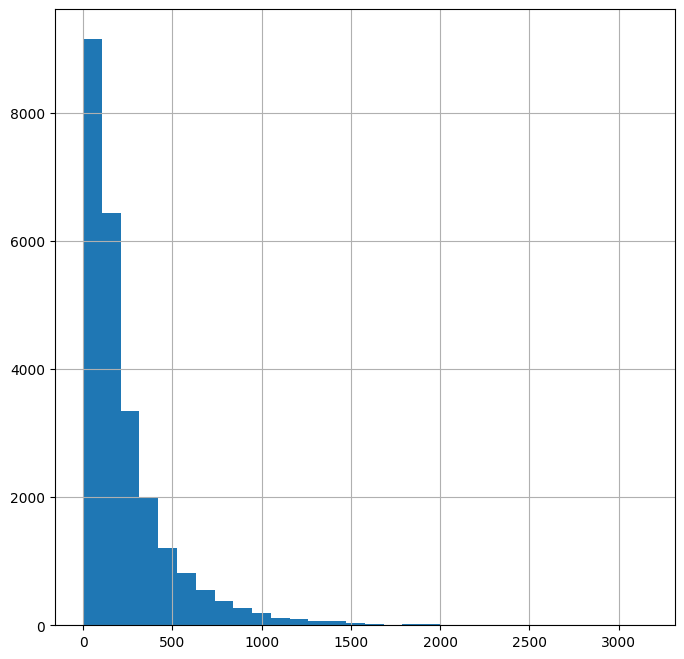

In [59]:
# lemmatized 된 리뷰의 길이
review['filter_lemmatized_text'].str.len().hist(bins=30, figsize=[8, 8])

# **True, Fake 리뷰별 단어의 언급 빈도**

In [60]:
#True Review 선별

true = review[review['fake'] == 0]

# 텍스트 집합 생성
text = ' '.join(true["filter_lemmatized_text"])

# 토큰화 (단어 단위로 분리)
tokens = text.split()

# 단어 빈도 계산
word_counts = Counter(tokens)

# 데이터 프레임 생성
df_freq = pd.DataFrame(word_counts.items(), columns=['Word', 'Frequency'])

# 빈도에 따라 데이터 프레임 내림차순 정렬
df_sorted = df_freq.sort_values(by='Frequency', ascending=False)

# 정렬된 데이터 프레임 출력
df_sorted.head(20)

In [61]:
#Fake Review 선별

fake = review[review['fake'] == 1]

# 텍스트 집합 생성
text = ' '.join(fake["filter_lemmatized_text"])

# 토큰화 (단어 단위로 분리)
tokens = text.split()

# 단어 빈도 계산
word_counts = Counter(tokens)

# 데이터 프레임 생성
df_freq = pd.DataFrame(word_counts.items(), columns=['Word', 'Frequency'])

# 빈도에 따라 데이터 프레임 내림차순 정렬
df_sorted = df_freq.sort_values(by='Frequency', ascending=False)

# 정렬된 데이터 프레임 출력
df_sorted.head(20)

# **TF-IDF로 중요한 단어만 선별**
- 많이 언급된 단어는 정상 리뷰와 Fake 리뷰간의 차이가 없어 보인다
- 많이 언급된 단어가 항상 중요하지 않을 수 있다
- Hotel이라는 단어는 True, Fake 리뷰 모두에 매우 많이 등장할 가능성이 높다
- TF-IDF 방식으로, 해당 Document에 중요한 단어를 필터링하여 파악하자


In [62]:
# TfidfVectorizer 초기화
vectorizer = TfidfVectorizer()

# 문서 집합에 대해 TF-IDF 계산
tfidf_matrix = vectorizer.fit_transform(true['filter_lemmatized_text'])

# TF-IDF 행렬과 특성 이름(단어) 확인
feature_names = vectorizer.get_feature_names_out()
tfidf_matrix_array = tfidf_matrix.toarray()

# TF-IDF 행렬을 DataFrame으로 변환
tfidf_true = pd.DataFrame(tfidf_matrix_array, columns=feature_names)

# DataFrame 출력
tfidf_true

In [63]:
# 각 단어의 평균 TF-IDF 값 계산
average_true_tfidf = tfidf_true.mean(axis=0)

# 평균 TF-IDF 값이 가장 높은 단어 상위 n개 선택
top_n_true_words = average_true_tfidf.nlargest(500)

In [64]:
pd.DataFrame(top_n_true_words).head(10)

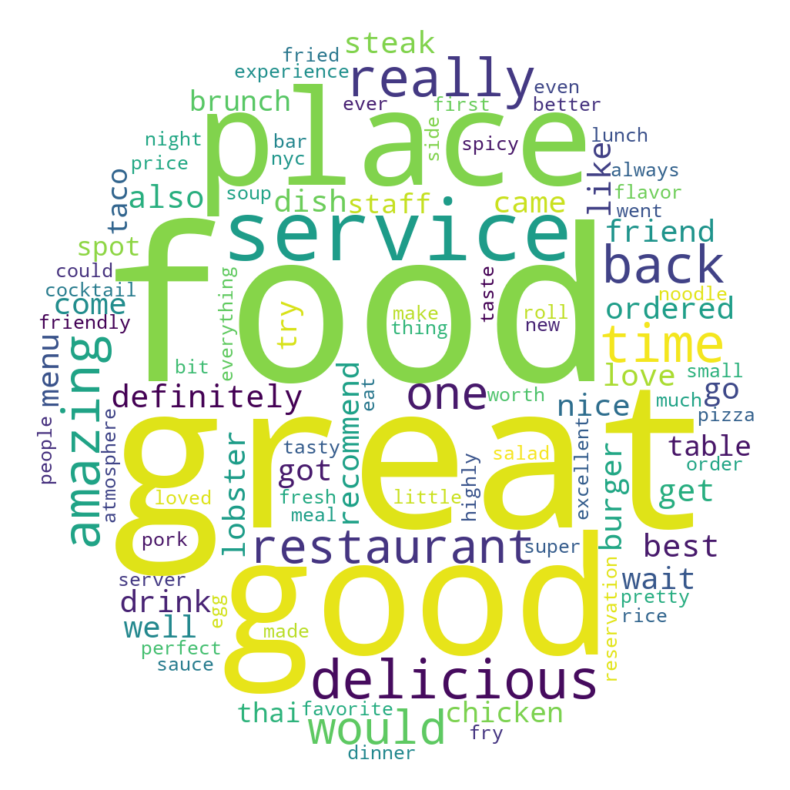

In [65]:
# 원형 마스크 생성
x, y = np.ogrid[:1000, :1000]  # 1000x1000 이미지

mask = (x - 500) ** 2 + (y - 500) ** 2 > 480 ** 2  # 원의 중심을 (500, 500)으로 하고 반지름은 480
mask = 255 * mask.astype(int)

# 워드 클라우드 생성
wordcloud = WordCloud(width=1000,
                      height=1000,
                      max_words= 100,
                      mask=mask,
                      background_color ='white').generate_from_frequencies(top_n_true_words)

# 워드 클라우드 시각화
plt.figure(figsize=(10, 10))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off') # 축 표시 제거
plt.show()

In [66]:
# TfidfVectorizer 초기화
vectorizer = TfidfVectorizer()

# 문서 집합에 대해 TF-IDF 계산
tfidf_matrix = vectorizer.fit_transform(fake['filter_lemmatized_text'])

# TF-IDF 행렬과 특성 이름(단어) 확인
feature_names = vectorizer.get_feature_names_out()
tfidf_matrix_array = tfidf_matrix.toarray()

# TF-IDF 행렬을 DataFrame으로 변환
tfidf_fake = pd.DataFrame(tfidf_matrix_array, columns=feature_names)

# DataFrame 출력
tfidf_fake

In [67]:
# 각 단어의 평균 TF-IDF 값 계산
average_fake_tfidf = tfidf_fake.mean(axis=0)

# 평균 TF-IDF 값이 가장 높은 단어 상위 n개 선택
top_n_fake_words = average_fake_tfidf.nlargest(500)

In [68]:
pd.DataFrame(top_n_fake_words).head(10)

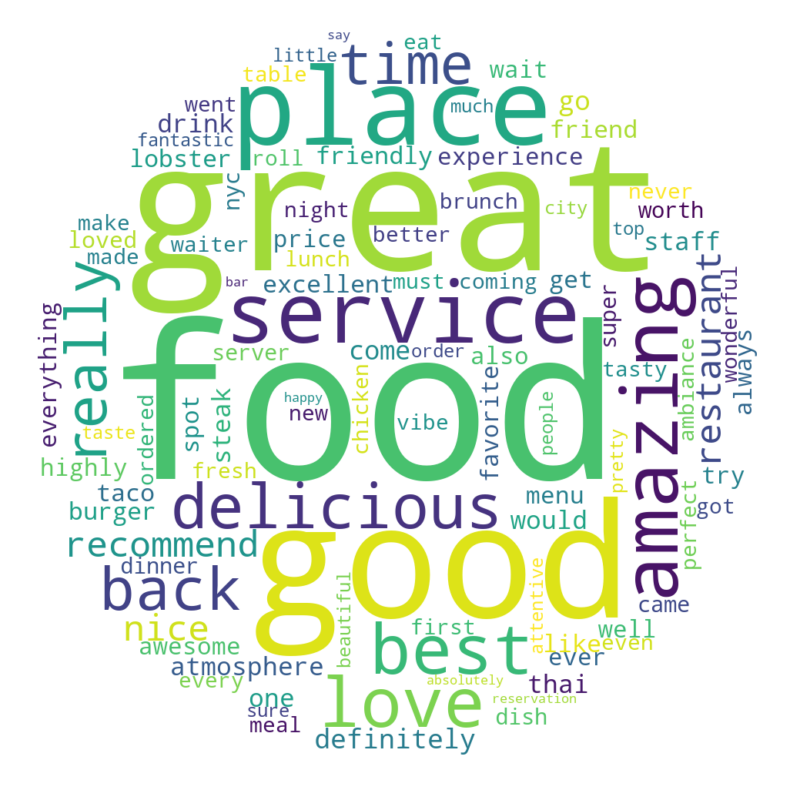

In [69]:
# 원형 마스크 생성
x, y = np.ogrid[:1000, :1000]  # 1000x1000 이미지

mask = (x - 500) ** 2 + (y - 500) ** 2 > 480 ** 2  # 원의 중심을 (500, 500)으로 하고 반지름은 480
mask = 255 * mask.astype(int)

# 워드 클라우드 생성
wordcloud = WordCloud(width=1000,
                      height=1000,
                      max_words= 100,
                      mask=mask,
                      background_color ='white').generate_from_frequencies(top_n_fake_words)

# 워드 클라우드 시각화
plt.figure(figsize=(10, 10))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off') # 축 표시 제거
plt.show()

# **TF-IDF 중요도 막대 그래프**
- TF-IDF 선별 이후에도, 많이 등장하는 단어는 육안으로 확인했을 때 True와 Fake 사이에 큰 차이가 없음

In [70]:
# true 리뷰 언급 단어 빈도 데이터프레임
top_n_true_words_df = pd.DataFrame(top_n_true_words).reset_index()
top_n_true_words_df.columns = ['true_word', 'frequency']

In [71]:
# fake 리뷰 언급 단어 빈도 데이터프레임
top_n_fake_words_df = pd.DataFrame(top_n_fake_words).reset_index()
top_n_fake_words_df.columns = ['fake_word', 'frequency']

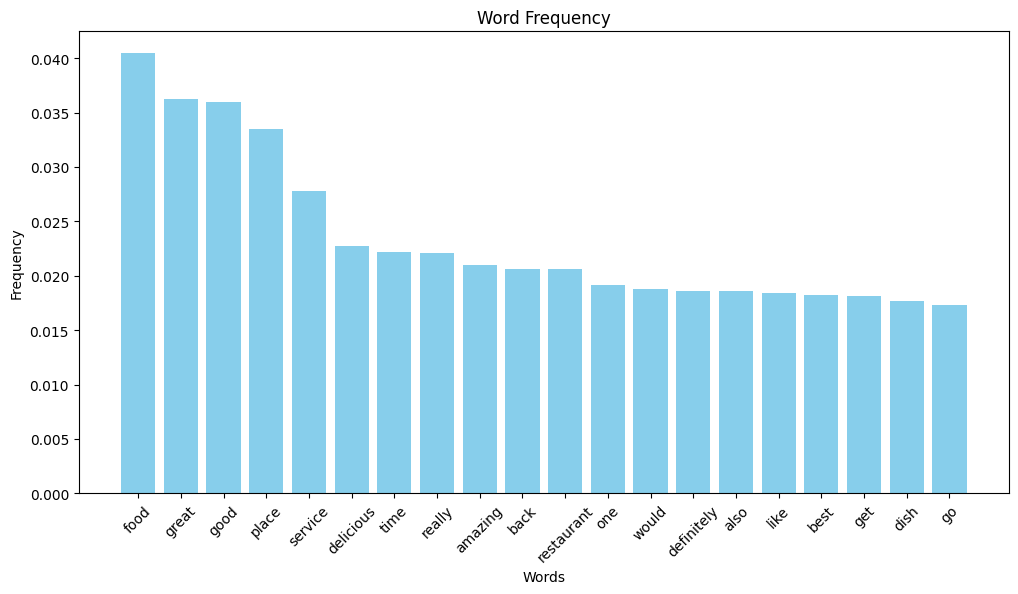

In [72]:
# True 막대그래프 생성
plt.figure(figsize=(12, 6))  # 그래프 크기 지정
plt.bar(top_n_true_words_df['true_word'][:20], top_n_true_words_df['frequency'][:20], color='skyblue')  # 막대그래프 설정
plt.xlabel('Words')  # x축 제목
plt.ylabel('Frequency')  # y축 제목
plt.title('Word Frequency')  # 그래프 제목
plt.xticks(rotation=45)  # x축 레이블 회전
plt.show()

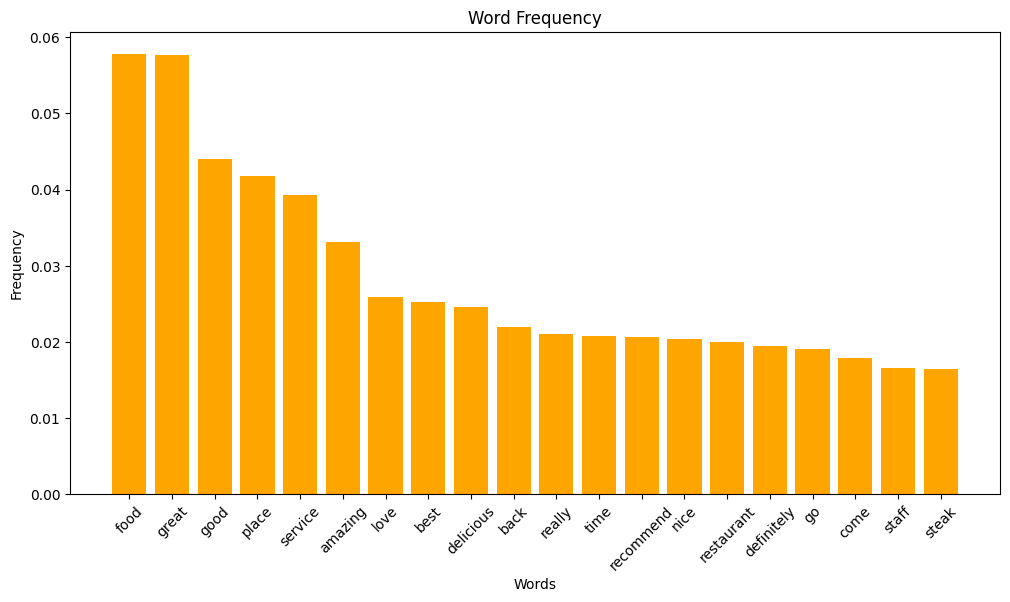

In [73]:
# Fake 막대그래프 생성
plt.figure(figsize=(12, 6))  # 그래프 크기 지정
plt.bar(top_n_fake_words_df['fake_word'][:20], top_n_fake_words_df['frequency'][:20], color='orange')  # 막대그래프 설정
plt.xlabel('Words')  # x축 제목
plt.ylabel('Frequency')  # y축 제목
plt.title('Word Frequency')  # 그래프 제목
plt.xticks(rotation=45)  # x축 레이블 회전
plt.show()

# **True, Fake에 따른 동시 출현 빈도 분석**
- 1위부터 10위 까지의 분포에 큰 차이가 없다
- 마찬가지로, 30위부터 50위까지 차이를 막대그래프로 그림
- 명확한 결과를 얻기 위해 다른 순위대에서 차이를 확인하는 것이 필요해 보임


In [74]:
# 각 리뷰를 단어의 리스트로 변환
tokenized_doc = true["filter_lemmatized_text"].apply(lambda x: x.split())

# 동시 출현 빈도를 계산할 딕셔너리
co_occurrence = defaultdict(int)

# 윈도우 크기 설정
window_size = 2

# 동시 출현 빈도 계산
for sentence in tokenized_doc:
    for i in range(len(sentence)):
        target_word = sentence[i]
        # 윈도우 내의 단어들과의 동시 출현 빈도 계산
        start = max(0, i - window_size)
        end = min(len(sentence), i + window_size + 1)
        for j in range(start, end):
            if i != j:
                co_occurred_word = sentence[j]
                pair = tuple(sorted([target_word, co_occurred_word]))
                co_occurrence[pair] += 1

i = 0
# 결과 출력
for pair, freq in co_occurrence.items():
    print(f"{pair}: {freq}")
    i += 1
    if i == 10:
        break

('delivery', 'ordered'): 40
('ordered', 'via'): 10
('delivery', 'via'): 4
('delivery', 'kimchi'): 2
('kimchi', 'via'): 2
('bimbimbap', 'via'): 2
('bimbimbap', 'kimchi'): 2
('great', 'kimchi'): 22
('bimbimbap', 'great'): 2
('bimbimbap', 'well'): 2


In [75]:
true_co_occurrence_df = pd.DataFrame(co_occurrence.items(), columns=['pair', 'frequency'])
true_co_occurrence_df = true_co_occurrence_df.sort_values(by='frequency', ascending=False)
true_co_occurrence_df.head(10)

In [76]:
# 각 리뷰를 단어의 리스트로 변환
tokenized_doc = fake["filter_lemmatized_text"].apply(lambda x: x.split())

# 동시 출현 빈도를 계산할 딕셔너리
co_occurrence = defaultdict(int)

# 윈도우 크기 설정
window_size = 2

# 동시 출현 빈도 계산
for sentence in tokenized_doc:
    for i in range(len(sentence)):
        target_word = sentence[i]
        # 윈도우 내의 단어들과의 동시 출현 빈도 계산
        start = max(0, i - window_size)
        end = min(len(sentence), i + window_size + 1)
        for j in range(start, end):
            if i != j:
                co_occurred_word = sentence[j]
                pair = tuple(sorted([target_word, co_occurred_word]))
                co_occurrence[pair] += 1

i = 0
# 결과 출력
for pair, freq in co_occurrence.items():
    print(f"{pair}: {freq}")
    i += 1
    if i == 10:
        break

('delivery', 'ordered'): 10
('canceled', 'ordered'): 2
('canceled', 'delivery'): 2
('delivery', 'order'): 22
('canceled', 'order'): 2
('canceled', 'without'): 2
('order', 'without'): 6
('order', 'reason'): 6
('reason', 'without'): 4
('half', 'without'): 2


In [77]:
fake_co_occurrence_df = pd.DataFrame(co_occurrence.items(), columns=['pair', 'frequency'])
fake_co_occurrence_df = fake_co_occurrence_df.sort_values(by='frequency', ascending=False)
fake_co_occurrence_df.head(10)

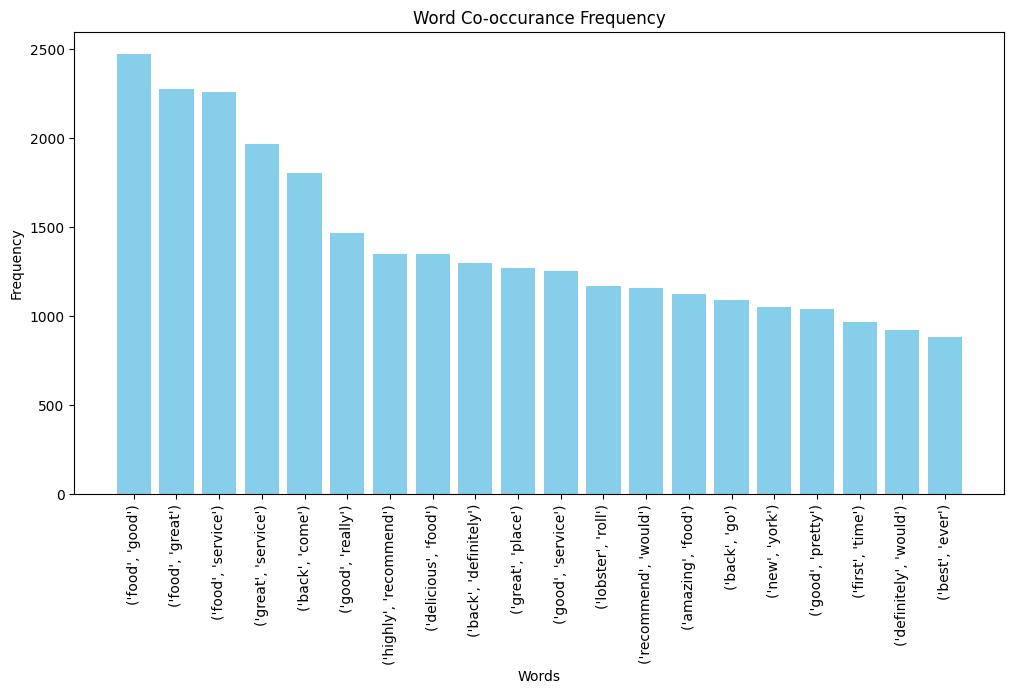

In [78]:
# True 동시출현빈도 막대그래프 생성
plt.figure(figsize=(12, 6))  # 그래프 크기 지정
plt.bar(true_co_occurrence_df['pair'][:20].astype('str'), true_co_occurrence_df['frequency'][:20], color='skyblue')  # 막대그래프 설정
plt.xlabel('Words')  # x축 제목
plt.ylabel('Frequency')  # y축 제목
plt.title('Word Co-occurance Frequency')  # 그래프 제목
plt.xticks(rotation=90)  # x축 레이블 회전
plt.show()

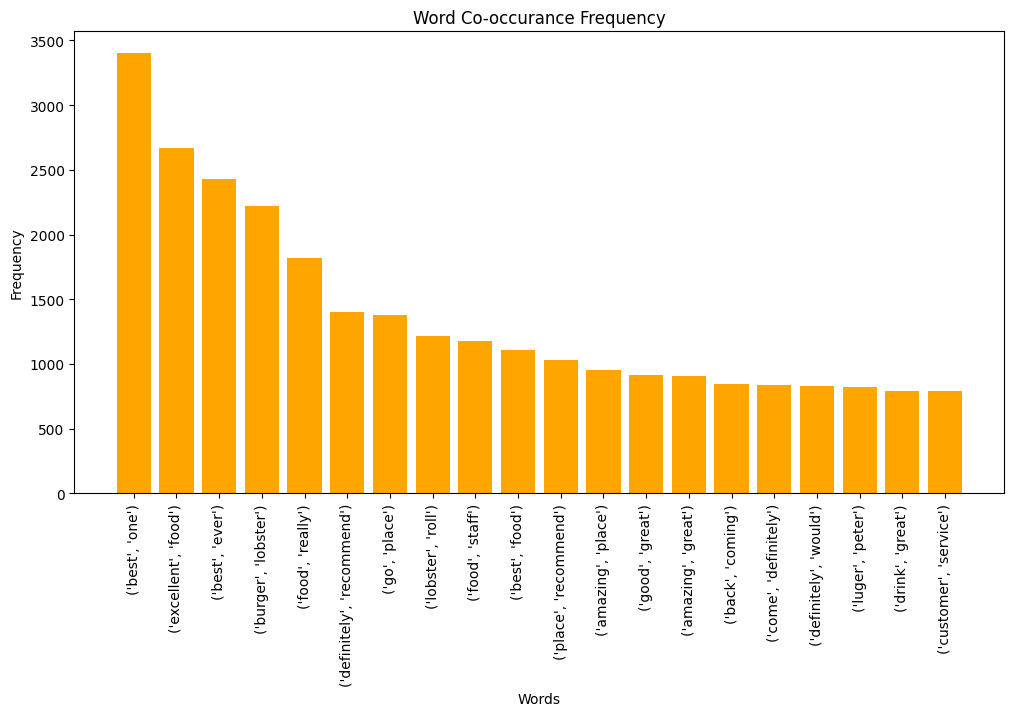

In [79]:
# Fake 동시출현빈도 막대그래프 생성
plt.figure(figsize=(12, 6))  # 그래프 크기 지정
plt.bar(fake_co_occurrence_df['pair'][30:50].astype('str'), fake_co_occurrence_df['frequency'][:20], color='orange')  # 막대그래프 설정
plt.xlabel('Words')  # x축 제목
plt.ylabel('Frequency')  # y축 제목
plt.title('Word Co-occurance Frequency')  # 그래프 제목
plt.xticks(rotation=90)  # x축 레이블 회전
plt.show()

# **숫자변수와 Label의 관계 시각화**
- 텍스트에서 추출해낸 Feature와 Label(True, Fake) 와의 차이를 분석

In [80]:
num_features = ['rating', 'photo', 'location', 'depth', 'text_structure', 'Cognition',
                'Affect', 'emotion', 'Social', 'Perception', 'motion',
                'Psychological Distancing', 'review_extremity', 'style', 'reputation', 'experience']

# label 별도로 분리
label = review['fake']

review_num = review[num_features]
review_num.head()

In [81]:
Minmax = MinMaxScaler()

review_num = Minmax.fit_transform(review_num)
review_num = pd.DataFrame(review_num, columns=num_features)
review_num.head()

## **변수 중요도 확인**

In [82]:
model = LogisticRegression(random_state=42)
model.fit(review_num, label)

result = permutation_importance(model, review_num, label, n_repeats=10, random_state=42, n_jobs=2)

feature_names = review_num.columns
importances = result.importances_mean
std = result.importances_std

fi_imp = pd.DataFrame({'feature': feature_names, 'importance': importances}).sort_values(by='importance', ascending=False).reset_index(drop=True)
fi_imp

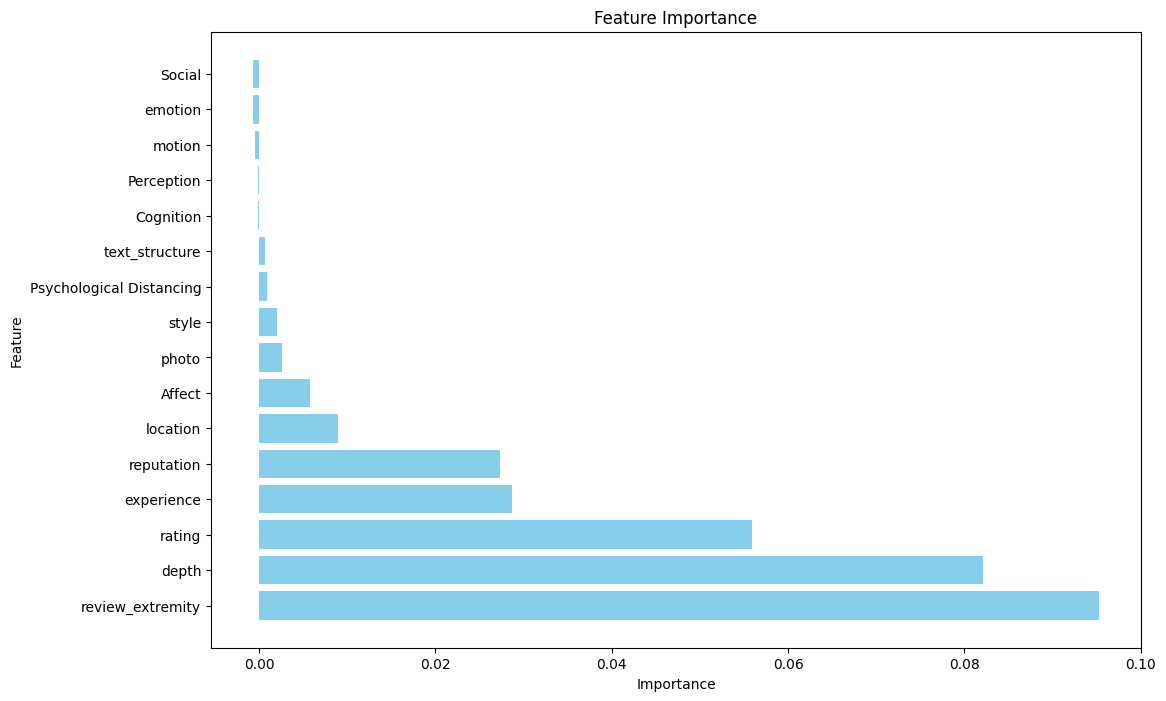

In [83]:
from matplotlib import pyplot as plt

plt.figure(figsize=(12, 8))

plt.barh(fi_imp['feature'], fi_imp['importance'], color='skyblue')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Feature Importance')
plt.show()

# **품사 빈도수 비교**

In [84]:
data = review.copy()

In [85]:
data

In [86]:
# 품사 태깅 함수
def get_pos_tags(text):
    tokens = word_tokenize(text)
    return nltk.pos_tag(tokens)

# 품사 빈도 계산 함수
def calculate_pos_frequencies(pos_tags):
    pos_counts = Counter(tag for word, tag in pos_tags)
    
    # 명사, 동사, 형용사, 부사
    nouns = pos_counts.get('NN', 0)
    verbs = pos_counts.get('VB', 0)
    adjectives = pos_counts.get('JJ', 0)
    adverbs = pos_counts.get('RB', 0)
    
    return {
        'N': nouns,
        'V': verbs,
        'ADJ': adjectives,
        'ADV': adverbs,
        'LEN': len(pos_tags)
    }

def preprocess_data(data):
    # 품사 태깅 및 품사 빈도 계산
    data['pos_tags'] = data['filter_stemmed_text'].apply(get_pos_tags)
    data['pos_frequencies'] = data['pos_tags'].apply(calculate_pos_frequencies)
    
    return data

def compare_reviews(data):
    # 'fake' 열의 값에 따라 두 그룹 간의 통계적 차이를 비교합니다.
    real_reviews = data[data['fake'] == 0]
    fake_reviews = data[data['fake'] == 1]

    # 각 그룹의 리뷰의 품사 빈도를 출력합니다.
    print("Real Reviews:")
    print(real_reviews['pos_frequencies'].apply(pd.Series).mean())
    print("\nFake Reviews:")
    print(fake_reviews['pos_frequencies'].apply(pd.Series).mean())

In [87]:
# 데이터 전처리 (품사)
data1 = preprocess_data(data)

In [88]:
# 리뷰 비교
compare_reviews(data1)

Real Reviews:
N      27.424430
V       1.714470
ADJ    10.839520
ADV     2.690313
LEN    52.036476
dtype: float64

Fake Reviews:
N      11.828167
V       0.809566
ADJ     4.618407
ADV     1.237217
LEN    22.286980
dtype: float64


In [89]:
def generate_comparison_df(data):
    # 'fake' 열의 값에 따라 두 그룹 간의 통계적 차이를 비교합니다.
    real_reviews = data1[data1['fake'] == 0]
    fake_reviews = data1[data1['fake'] == 1]

    # 각 그룹의 리뷰의 품사 빈도를 데이터프레임으로 변환합니다.
    real_pos_df = real_reviews['pos_frequencies'].apply(pd.Series)
    fake_pos_df = fake_reviews['pos_frequencies'].apply(pd.Series)

    # 두 데이터프레임을 병합합니다.
    comparison_df = pd.concat([real_pos_df.mean(), fake_pos_df.mean()], axis=1)
    comparison_df.columns = ['Real', 'Fake']  # 열 이름을 변경합니다.

    return comparison_df

# 실행 예제
comparison_df = generate_comparison_df(data)

In [90]:
comparison_df

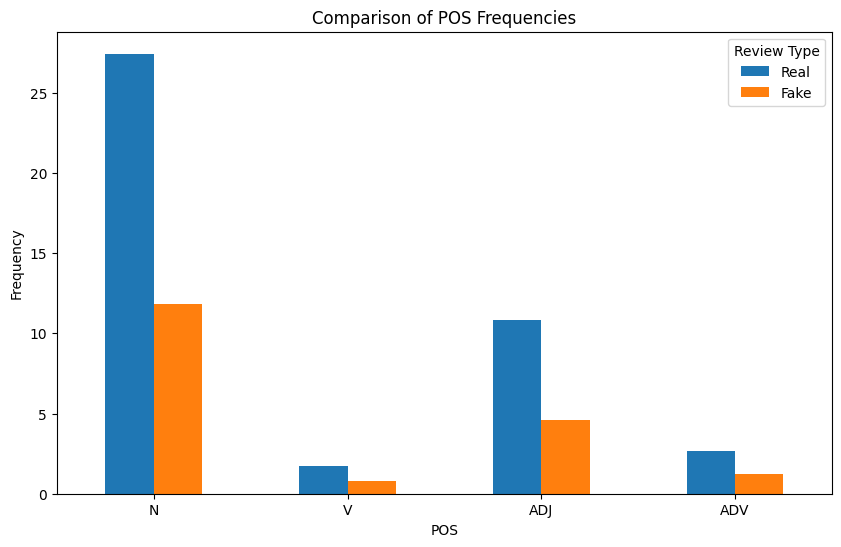

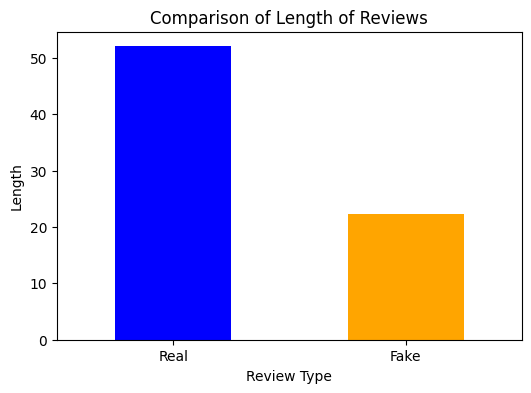

In [91]:
def visualize_comparison(comparison_df):
    # LEN을 제외한 항목들을 그룹화하여 그래프로 그립니다.
    comparison_df.drop('LEN').plot(kind='bar', figsize=(10, 6))
    plt.title('Comparison of POS Frequencies')
    plt.xlabel('POS')
    plt.ylabel('Frequency')
    plt.xticks(rotation=0)  # x축 눈금 라벨을 가로로 표시
    plt.legend(title='Review Type')
    plt.show()

    # LEN을 그래프로 그립니다.
    comparison_df.loc['LEN'].plot(kind='bar', color=['blue', 'orange'], figsize=(6, 4))
    plt.title('Comparison of Length of Reviews')
    plt.xlabel('Review Type')
    plt.ylabel('Length')
    plt.xticks(rotation=0)  # x축 눈금 라벨을 가로로 표시
    plt.show()

# 실행 예제
visualize_comparison(comparison_df)

# **변수 분포 시각화**

## Experience

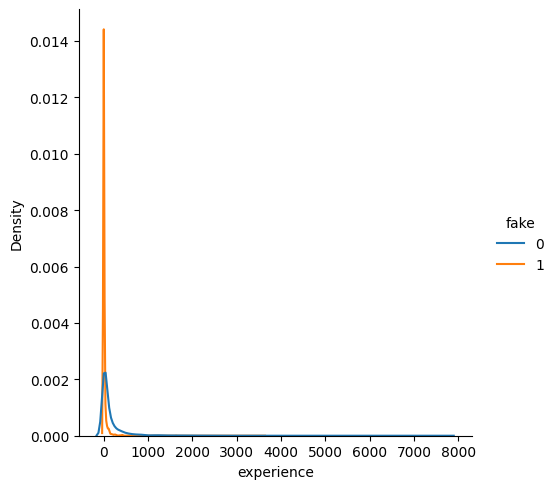

In [92]:
sns.displot(data=review, x="experience", hue="fake", kind="kde")

(0.0, 20.0)

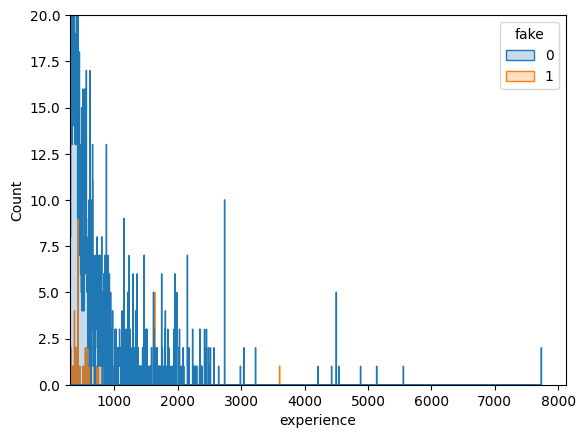

In [93]:
sns.histplot(data=review, x="experience", hue="fake", element="step", stat="count", common_norm=False)
plt.xlim(300, )
plt.ylim(0, 20)

## depth

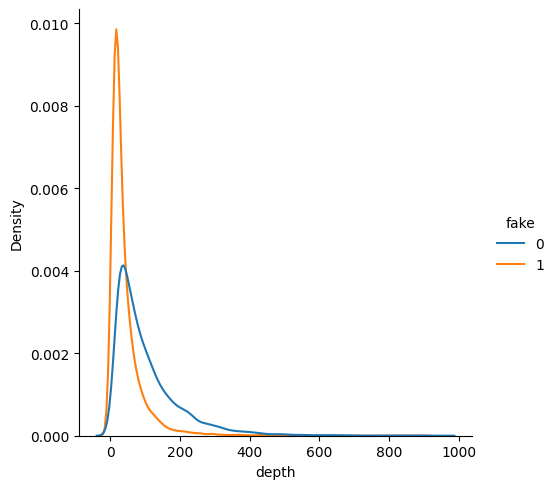

In [94]:
sns.displot(data=review, x="depth", hue="fake", kind="kde")

## Reputation

<Axes: xlabel='reputation', ylabel='Count'>

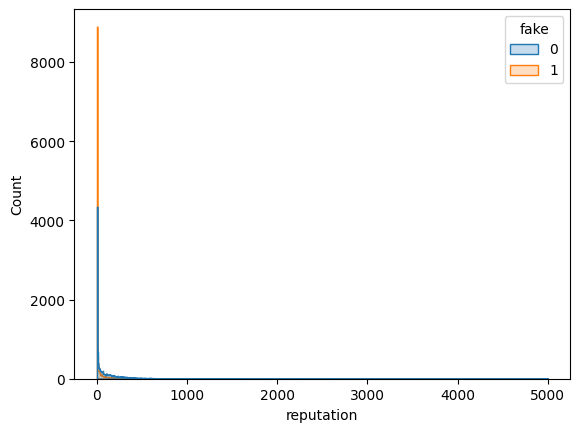

In [95]:
sns.histplot(data=review, x="reputation", hue="fake", element="step", stat="count", common_norm=False)

(0.0, 30.0)

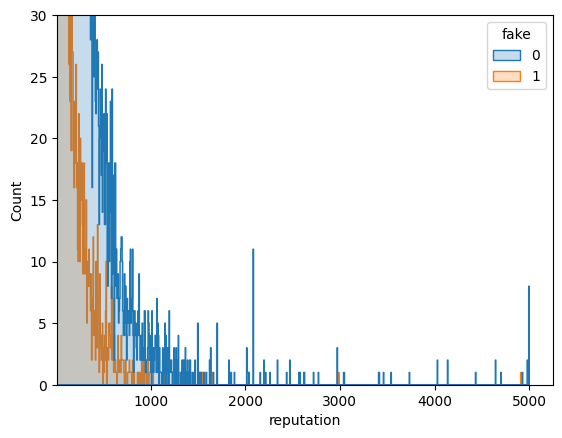

In [96]:
sns.histplot(data=review, x="reputation", hue="fake", element="step", stat="count", common_norm=False)
plt.xlim(10, )
plt.ylim(0, 30)

## Affect

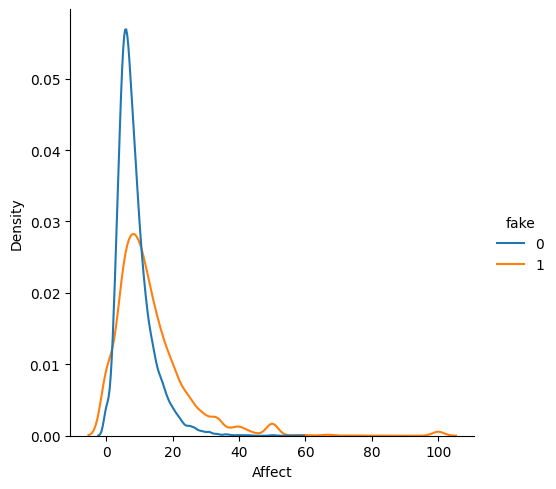

In [97]:
sns.displot(data=review, x="Affect", hue="fake", kind='kde')

## text structure

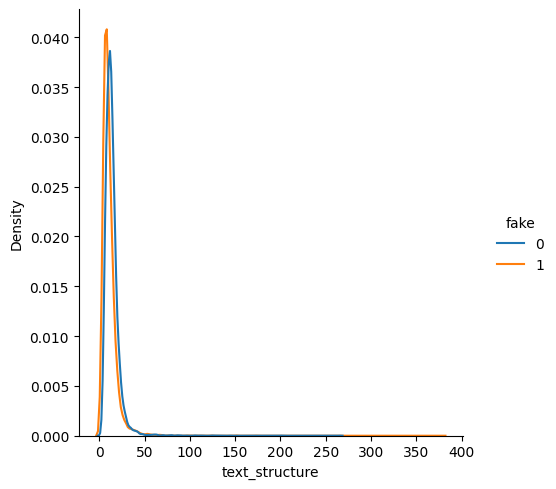

In [98]:
sns.displot(data=review, x="text_structure", hue="fake", kind='kde')

(0.0, 20.0)

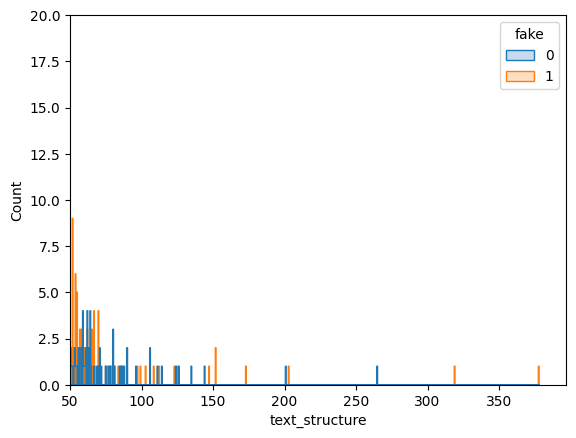

In [99]:
# 50 이상일 때 분포에 차이가 있는 것으로 추정
sns.histplot(data=review, x="text_structure", hue="fake", element="step", stat="count", common_norm=False)
plt.xlim(50, )
plt.ylim(0, 20)

## style

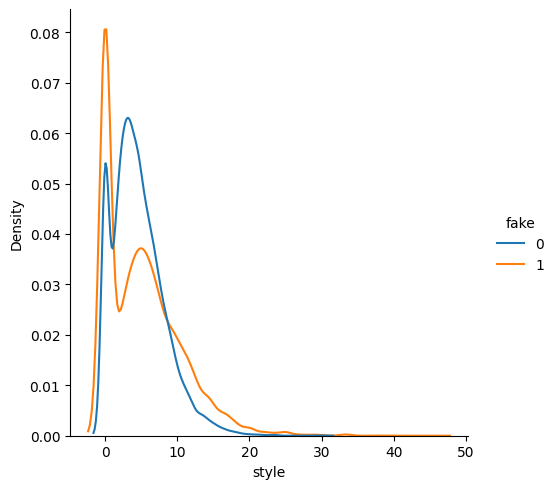

In [100]:
sns.displot(data=review, x="style", hue="fake", kind='kde')

## **누적 변수분포 시각화**

## experience

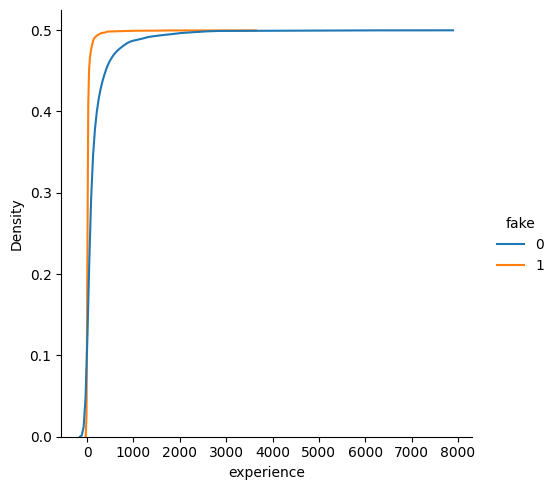

In [101]:
sns.displot(data=review, x="experience", hue="fake", kind="kde", cumulative=True)

## depth

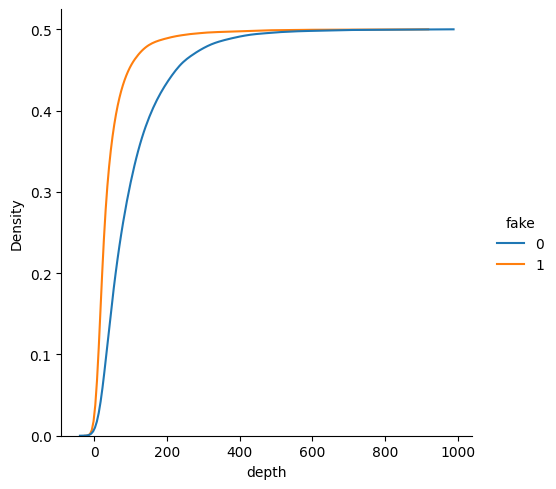

In [102]:
sns.displot(data=review, x="depth", hue="fake", kind="kde", cumulative=True)

## reputation

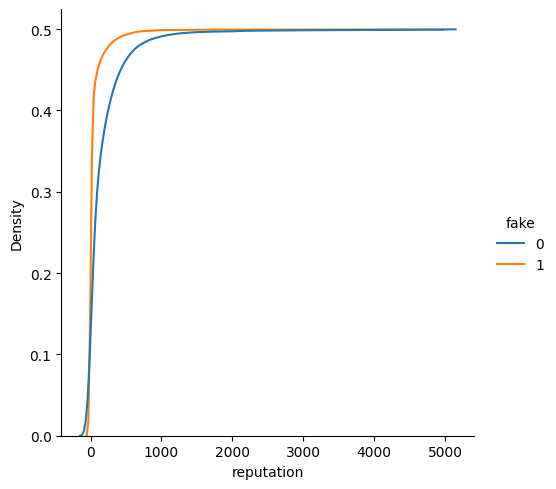

In [103]:
sns.displot(data=review, x="reputation", hue="fake", kind="kde", cumulative=True)

## text_structure

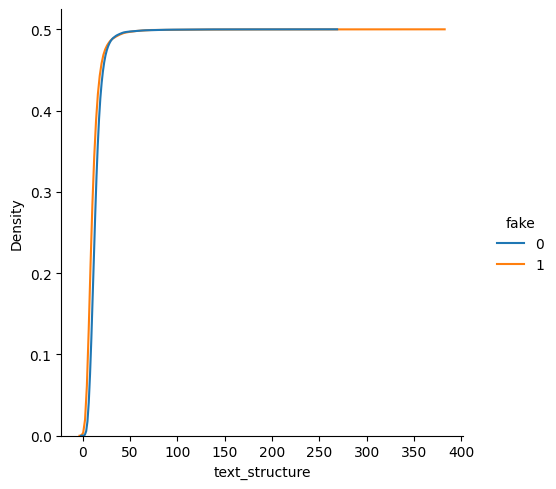

In [104]:
sns.displot(data=review, x="text_structure", hue="fake", kind="kde", cumulative=True)

## style

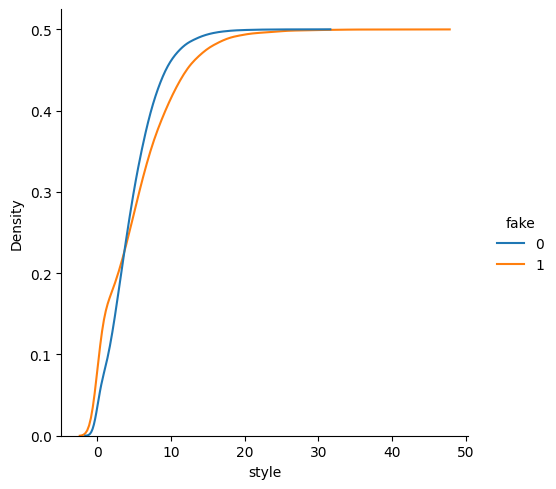

In [105]:
sns.displot(data=review, x="style", hue="fake", kind="kde", cumulative=True)